# 3 · Classificação: qualidade de uvas na receção da adega
**AgroNet Forward · AI Insights for Agro**

**Pergunta de negócio:** *ao receber um lote de uvas, posso classificá-lo (A, B ou C) de forma rápida e consistente
com poucas medições?*

Aqui o modelo aprende com lotes **já classificados** a classificar lotes **novos**. Vamos dar atenção especial a:
- modelos **que se explicam** (uma árvore de decisão lê-se como um fluxograma);
- **que erros custam mais**;
- **quantas medições** são realmente necessárias.

> ⚠️ **Dados sintéticos.** Valores e regras de classificação inventados para a demonstração. Os lotes **não** representam
> nenhuma adega e as classes (A/B/C) são uma simplificação.

> 💡 **No Google Colab:** *Ficheiro → Carregar para a sessão* e carregue o CSV desta pasta `dados/`. Se não o fizer, o notebook gera automaticamente os mesmos dados.

## 0 · Preparação

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

# --- Gerador de reserva -------------------------------------------
# Se o ficheiro CSV não estiver na pasta (p.ex. no Google Colab), os dados
# são gerados aqui, com a mesma semente => exatamente os mesmos dados.
# (Pode ignorar este código; o notebook começa na secção 1.)

def gerar_uvas(seed=11, n=900):
    rng = np.random.default_rng(seed)
    castas = ["Touriga Nacional", "Touriga Franca", "Tinta Roriz", "Tinto Cão"]
    casta = rng.choice(castas, n, p=[0.3, 0.3, 0.25, 0.15])
    # Qualidade latente (maturação/sanidade) - não observada diretamente
    q = rng.normal(0, 1, n)
    brix = np.clip(21.5 + 1.6 * q + rng.normal(0, 0.7, n), 15, 29)
    acidez = np.clip(6.2 - 0.5 * q + rng.normal(0, 0.6, n), 3.0, 9.5)
    ph = np.clip(3.35 + 0.08 * q + rng.normal(0, 0.07, n), 2.9, 3.9)
    peso_bago = np.clip(1.35 - 0.04 * q + rng.normal(0, 0.12, n), 0.7, 2.0)
    cor = np.clip(60 + 9 * q + rng.normal(0, 6, n), 20, 100)
    danificados = np.clip(6 - 2.0 * q + rng.exponential(2.0, n), 0, 40)
    temp_rec = np.clip(rng.normal(22, 4, n), 10, 38)
    dias_colheita = rng.integers(0, 3, n)

    # Qualidade final (regras + ruído): reflete o que um enólogo valoriza
    pontos = (
        0.9 * (brix - 21.5)
        - 0.7 * np.maximum(acidez - 7.0, 0)
        + 1.9
        - 0.25 * danificados
        + 0.05 * (cor - 60)
        - 0.06 * np.maximum(temp_rec - 26, 0)
        + rng.normal(0, 0.8, n)
    )
    classe = np.where(pontos > 1.2, "A", np.where(pontos > -1.0, "B", "C"))
    return pd.DataFrame({
        "lote_id": [f"L{1000 + i}" for i in range(n)],
        "casta": casta,
        "grau_brix": brix.round(1),
        "acidez_total_gl": acidez.round(1),
        "ph": ph.round(2),
        "peso_bago_g": peso_bago.round(2),
        "indice_cor": cor.round(0),
        "bagos_danificados_pct": danificados.round(1),
        "temp_rececao_c": temp_rec.round(1),
        "dias_desde_colheita": dias_colheita,
        "classe_qualidade": classe,
    })

## 1 · Os dados

In [2]:
CAMINHO = "../dados/qualidade_uvas.csv"
if os.path.exists(CAMINHO):
    df = pd.read_csv(CAMINHO)
else:
    print("CSV não encontrado -> a gerar os dados na hora.")
    df = gerar_uvas()

print(df.shape)
df.head()

(900, 11)


,lote_id,casta,grau_brix,acidez_total_gl,ph,peso_bago_g,indice_cor,bagos_danificados_pct,temp_rececao_c,dias_desde_colheita,classe_qualidade
0,L1000,Touriga Nacional,22.4,5.9,3.43,1.23,59.0,8.3,22.1,1,B
1,L1001,Touriga Franca,23.2,5.4,3.44,1.10,68.0,7.4,27.3,1,A
2,L1002,Tinta Roriz,19.6,8.0,3.16,1.34,37.0,12.6,25.4,1,C
3,L1003,Touriga Nacional,21.1,7.3,3.34,1.43,48.0,8.8,25.2,2,C
4,L1004,Touriga Nacional,19.8,6.6,3.25,1.39,58.0,11.0,19.2,1,B


In [3]:
print(df.classe_qualidade.value_counts().sort_index().to_string())
df.groupby("classe_qualidade")[["grau_brix", "acidez_total_gl", "indice_cor",
                                "bagos_danificados_pct", "temp_rececao_c"]].mean().round(1)

classe_qualidade
A    287
B    277
C    336


,grau_brix,acidez_total_gl,indice_cor,bagos_danificados_pct,temp_rececao_c
classe_qualidade,,,,,
A,23.2,5.7,69.8,5.6,21.6
B,21.6,6.2,60.7,7.8,22.2
C,19.9,6.7,51.1,10.3,22.1


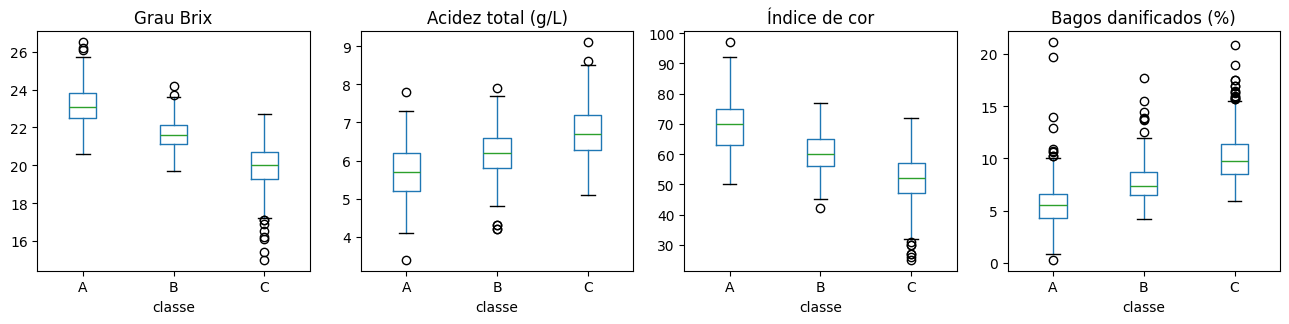

In [4]:
fig, eixos = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, col, tit in zip(eixos,
                        ["grau_brix", "acidez_total_gl", "indice_cor", "bagos_danificados_pct"],
                        ["Grau Brix", "Acidez total (g/L)", "Índice de cor", "Bagos danificados (%)"]):
    df.boxplot(column=col, by="classe_qualidade", ax=ax, grid=False)
    ax.set_title(tit); ax.set_xlabel("classe"); ax.set_ylabel("")
fig.suptitle("")
plt.tight_layout()
plt.show()

Há tendências claras (A: mais açúcar, mais cor, menos danos), mas **as distribuições sobrepõem-se**: nenhuma
medição, sozinha, separa as classes. É por isso que combinar variáveis ajuda.

## 2 · Treino e teste
Guardamos 25% dos lotes para teste (o modelo **não os vê** a treinar). `stratify` garante a mesma proporção de classes.

In [5]:
X = pd.get_dummies(df.drop(columns=["lote_id", "classe_qualidade"]), columns=["casta"])
y = df.classe_qualidade

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(len(X_tr), "lotes de treino |", len(X_te), "lotes de teste")

675 lotes de treino | 225 lotes de teste


## 3 · Referência, árvore de decisão e floresta
- **Referência:** prever sempre a classe mais comum (o mínimo que um modelo tem de bater).
- **Árvore de decisão (profundidade 3):** pequena, **explicável**.
- **Random forest:** muitas árvores a "votar"; costuma ser mais precisa, mas menos legível.

In [6]:
modelos = {
    "Referência (classe mais comum)": DummyClassifier(strategy="most_frequent"),
    "Árvore de decisão (prof. 3)": DecisionTreeClassifier(max_depth=3, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
}
linhas = []
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    p = m.predict(X_te)
    linhas.append({"modelo": nome,
                   "exatidão": round(accuracy_score(y_te, p), 3),
                   "F1 (média das classes)": round(f1_score(y_te, p, average="macro"), 3)})
pd.DataFrame(linhas).set_index("modelo")

,exatidão,F1 (média das classes)
modelo,,
Referência (classe mais comum),0.373,0.181
Árvore de decisão (prof. 3),0.711,0.711
Random forest,0.760,0.761


### 3.1 · A árvore explica-se sozinha
Uma árvore pequena é, literalmente, **um fluxograma de perguntas**. Isto permite **explicar ao enólogo** e à
equipa porque é que um lote ficou em determinada classe, e discutir se as regras "fazem sentido".

In [7]:
arvore = modelos["Árvore de decisão (prof. 3)"]
print(export_text(arvore, feature_names=list(X.columns)))

|--- grau_brix <= 22.05
|   |--- grau_brix <= 20.45
|   |   |--- bagos_danificados_pct <= 7.25
|   |   |   |--- class: B
|   |   |--- bagos_danificados_pct >  7.25
|   |   |   |--- class: C
|   |--- grau_brix >  20.45
|   |   |--- bagos_danificados_pct <= 8.45
|   |   |   |--- class: B
|   |   |--- bagos_danificados_pct >  8.45
|   |   |   |--- class: C
|--- grau_brix >  22.05
|   |--- indice_cor <= 58.50
|   |   |--- grau_brix <= 23.05
|   |   |   |--- class: B
|   |   |--- grau_brix >  23.05
|   |   |   |--- class: A
|   |--- indice_cor >  58.50
|   |   |--- bagos_danificados_pct <= 7.75
|   |   |   |--- class: A
|   |   |--- bagos_danificados_pct >  7.75
|   |   |   |--- class: B



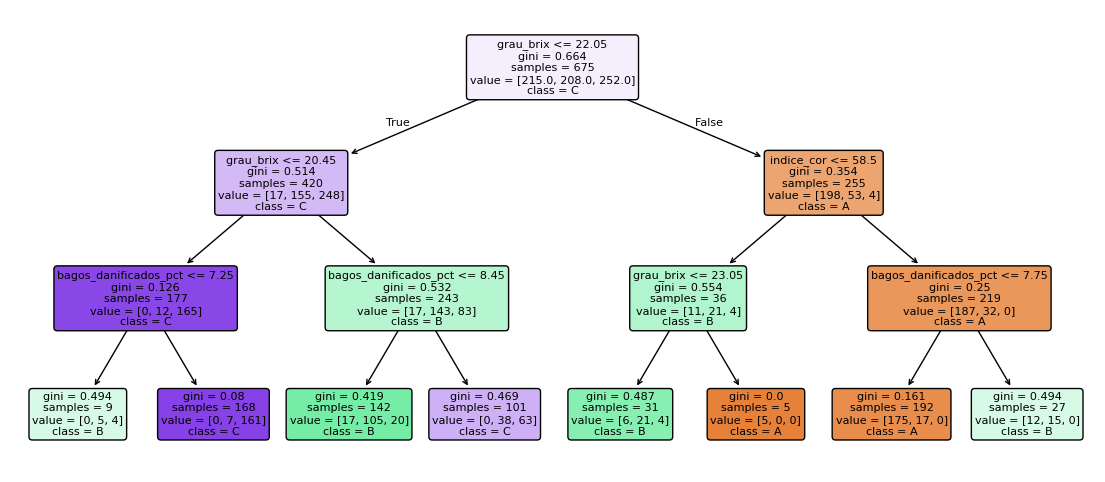

In [8]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore, feature_names=list(X.columns), class_names=list(arvore.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

## 4 · Que erros custam mais?
A **matriz de confusão** mostra onde o modelo acerta e onde confunde. Nem todos os erros pesam o mesmo:
classificar um lote **C como A** (qualidade baixa a seguir como superior) é bem pior do que **A como B**.

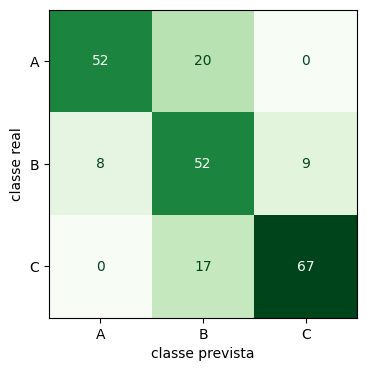

Erros graves (C classificado como A): 0


In [9]:
rf = modelos["Random forest"]
pred = rf.predict(X_te)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=["A", "B", "C"]),
                       display_labels=["A", "B", "C"]).plot(ax=ax, colorbar=False, cmap="Greens")
ax.set_xlabel("classe prevista"); ax.set_ylabel("classe real"); ax.grid(False)
plt.show()

graves = int(((y_te == "C") & (pred == "A")).sum())
print("Erros graves (C classificado como A):", graves)

## 5 · Quantas medições são necessárias?
Cada medição custa tempo e dinheiro. Compara-se o desempenho com **diferentes conjuntos de medições**
(validação cruzada com 5 partições, mais fiável do que um único teste).

In [10]:
conjuntos = {
    "Só °Brix": ["grau_brix"],
    "°Brix + acidez": ["grau_brix", "acidez_total_gl"],
    "°Brix + acidez + bagos danificados": ["grau_brix", "acidez_total_gl", "bagos_danificados_pct"],
    "Todas as medições": list(X.columns),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
linhas = []
for nome, cols in conjuntos.items():
    pontuacoes = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                                 X[cols], y, cv=cv, scoring="accuracy")
    linhas.append({"medições usadas": nome, "nº de variáveis": len(cols),
                   "exatidão média": round(pontuacoes.mean(), 3)})
pd.DataFrame(linhas).set_index("medições usadas")

,nº de variáveis,exatidão média
medições usadas,,
Só °Brix,1,0.736
°Brix + acidez,2,0.718
°Brix + acidez + bagos danificados,3,0.778
Todas as medições,12,0.806


> 🔍 **Leitura:** só o °Brix já classifica bem uma parte dos lotes. Acrescentar a acidez **não melhorou** (diferenças de
> 2–3 pontos percentuais estão dentro do ruído de uma amostra de 900 lotes). O salto aparece ao juntar os **bagos
> danificados** e as restantes medições. A pergunta de gestão é: **o ganho justifica o custo de medir tudo?**

## 6 · Profundidade da árvore: simples demais ou complexa demais?
- **Simples demais** (*underfitting*): não aprende o suficiente.
- **Complexa demais** (*overfitting*): "decora" os dados de treino e falha em lotes novos.

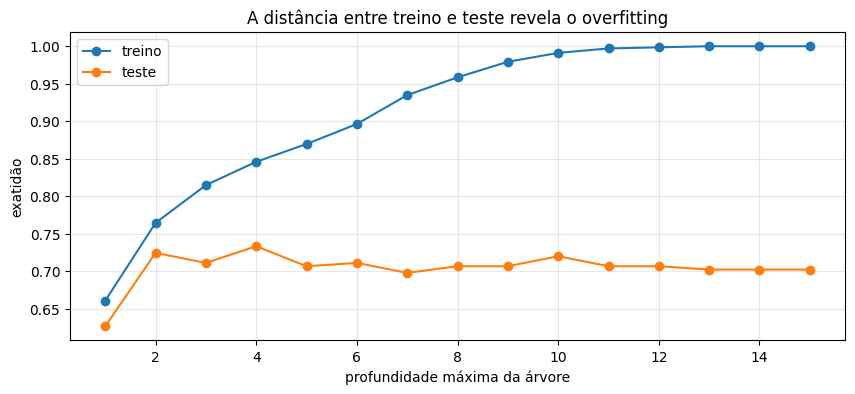

In [11]:
profs = range(1, 16)
acc_tr, acc_te = [], []
for p in profs:
    a = DecisionTreeClassifier(max_depth=p, random_state=0).fit(X_tr, y_tr)
    acc_tr.append(a.score(X_tr, y_tr)); acc_te.append(a.score(X_te, y_te))

fig, ax = plt.subplots()
ax.plot(profs, acc_tr, marker="o", label="treino")
ax.plot(profs, acc_te, marker="o", label="teste")
ax.set_xlabel("profundidade máxima da árvore"); ax.set_ylabel("exatidão"); ax.legend()
ax.set_title("A distância entre treino e teste revela o overfitting")
plt.show()

## 7 · Classificar um lote novo
Em produção, um técnico mede um lote e obtém logo a classe e a **confiança** do modelo.

In [12]:
novo = pd.DataFrame([{
    "grau_brix": 23.0, "acidez_total_gl": 6.0, "ph": 3.4, "peso_bago_g": 1.3,
    "indice_cor": 70, "bagos_danificados_pct": 5.0, "temp_rececao_c": 21.0, "dias_desde_colheita": 1,
    "casta_Tinta Roriz": 0, "casta_Tinto Cão": 0, "casta_Touriga Franca": 0, "casta_Touriga Nacional": 1,
}])[X.columns]

probs = rf.predict_proba(novo)[0]
for classe, p in zip(rf.classes_, probs):
    print(f"Classe {classe}: {p:.0%}")

Classe A: 87%
Classe B: 13%
Classe C: 0%


Este lote tem uma classe claramente dominante. Veja agora um **caso limite**:

In [13]:
limite = novo.copy()
limite[["grau_brix", "indice_cor", "bagos_danificados_pct"]] = [22.5, 62, 7.5]
limite[["casta_Touriga Nacional", "casta_Touriga Franca"]] = [0, 1]

for classe, p in zip(rf.classes_, rf.predict_proba(limite)[0]):
    print(f"Classe {classe}: {p:.0%}")

Classe A: 50%
Classe B: 47%
Classe C: 2%


Quando as probabilidades estão **repartidas** (aqui, A e B), é um caso **limite**: aí convém a **decisão humana**.
A IA ajuda a triar e a ser consistente; o especialista decide os casos duvidosos.

## 8 · Exercícios para experimentar
1. Mude os valores do lote novo (mais danos, menos Brix…). Onde passa de A para B?
2. Experimente `max_depth=2` e `max_depth=6`. Como muda a árvore e o resultado?
3. Remova `casta` das variáveis. A casta contribui?
4. **Reflexão:** com apenas °Brix, o modelo acerta quanto? Vale a pena medir o resto?